# Semantic Warehouse Inspection — Task 1
Development notebook for Robotics Software and Programming.

Run all cells in Google Colab. Four custom object models, nine scene objects and a custom two-wheel robot are generated below. The robot is repositioned between camera views; this is scene observation, not an autonomous navigation demonstration. Review and adapt the implementation, document your own decisions, and follow your module guidance on AI attribution.


**Verification note:** Python code cells were executed locally in order with preinstalled dependencies; the install cell was skipped. Outputs below are from that direct execution, not from a Colab run. See the packaged evidence log.


In [ ]:
%pip install -q pybullet matplotlib numpy

In [1]:
import json, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pybullet as p
import pybullet_data
assets = Path("warehouse_assets")
assets.mkdir(exist_ok=True)
if p.isConnected(): p.disconnect()
client = p.connect(p.DIRECT)
p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.setGravity(0, 0, -9.81)
p.loadURDF("plane.urdf")


In [2]:
def box_model(name, size, color):
    # Static semantic objects share a simple geometry generator but distinct models.
    xyz = " ".join(map(str, size))
    rgba = " ".join(map(str, color))
    text = f'''<?xml version="1.0"?>
<robot name="{name}"><link name="body">
<inertial><mass value="1"/><inertia ixx="1" ixy="0" ixz="0" iyy="1" iyz="0" izz="1"/></inertial>
<visual><geometry><box size="{xyz}"/></geometry><material name="color"><color rgba="{rgba}"/></material></visual>
<collision><geometry><box size="{xyz}"/></geometry></collision>
</link></robot>'''
    path = assets / f"{name}.urdf"
    path.write_text(text)
    return str(path)
models = {
    "barrier": box_model("barrier", [0.18, 2.0, 0.7], [0.6, 0.63, 0.7, 1]),
    "shelf": box_model("shelf", [0.7, 1.0, 0.9], [0.8, 0.45, 0.15, 1]),
    "inspection_zone": box_model("inspection_zone", [0.65, 0.65, 0.02], [0.15, 0.8, 0.3, 1]),
    "landmark": box_model("landmark", [0.2, 0.2, 1.0], [0.2, 0.35, 1, 1]),
}
# Two driven wheel joints and a passive support sphere.
robot_xml = '''<?xml version="1.0"?><robot name="inspector">
<link name="base"><inertial><mass value="3"/><inertia ixx="0.05" ixy="0" ixz="0" iyy="0.05" iyz="0" izz="0.05"/></inertial>
<visual><geometry><box size="0.4 0.3 0.15"/></geometry><material name="red"><color rgba="0.9 0.15 0.15 1"/></material></visual>
<collision><geometry><box size="0.4 0.3 0.15"/></geometry></collision></link>'''
for side, y in [("left", 0.18), ("right", -0.18)]:
    robot_xml += f'''<link name="{side}_wheel"><inertial><mass value="0.2"/><inertia ixx="0.001" ixy="0" ixz="0" iyy="0.001" iyz="0" izz="0.001"/></inertial>
<visual><origin rpy="1.5707963 0 0"/><geometry><cylinder radius="0.1" length="0.04"/></geometry><material name="black"><color rgba="0.1 0.1 0.1 1"/></material></visual>
<collision><origin rpy="1.5707963 0 0"/><geometry><cylinder radius="0.1" length="0.04"/></geometry></collision></link>
<joint name="{side}_drive" type="continuous"><parent link="base"/><child link="{side}_wheel"/><origin xyz="0 {y} -0.055"/><axis xyz="0 1 0"/></joint>'''
robot_xml += '''<link name="support"><inertial><mass value="0.05"/><inertia ixx="0.0001" ixy="0" ixz="0" iyy="0.0001" iyz="0" izz="0.0001"/></inertial><visual><geometry><sphere radius="0.035"/></geometry></visual><collision><geometry><sphere radius="0.035"/></geometry></collision></link>
<joint name="support_joint" type="fixed"><parent link="base"/><child link="support"/><origin xyz="-0.15 0 -0.12"/></joint></robot>'''
(assets / "inspector.urdf").write_text(robot_xml)


In [3]:
layout = [
    ("west_barrier", "barrier", "obstacle", [-2.4, 0, 0.35]),
    ("east_barrier", "barrier", "obstacle", [2.4, 0, 0.35]),
    ("shelf_A", "shelf", "obstacle", [-1.3, 0.8, 0.45]),
    ("shelf_B", "shelf", "obstacle", [1.3, 0.8, 0.45]),
    ("inspection_A", "inspection_zone", "target", [-1.3, -0.8, 0.011]),
    ("inspection_B", "inspection_zone", "target", [1.3, -0.8, 0.011]),
    ("home_zone", "inspection_zone", "home", [0, -1.8, 0.011]),
    ("reference_A", "landmark", "landmark", [-2.0, 1.8, 0.5]),
    ("reference_B", "landmark", "landmark", [2.0, 1.8, 0.5]),
]
semantics = {}
for name, model, role, position in layout:
    body = p.loadURDF(models[model], position, useFixedBase=True)
    semantics[body] = dict(name=name, model=model, role=role)
robot = p.loadURDF(str(assets / "inspector.urdf"), [0, -1.8, 0.155])
print(json.dumps(semantics, indent=2))

def nearest_object(role):
    robot_xy = np.array(p.getBasePositionAndOrientation(robot)[0][:2])
    candidates = [(float(np.linalg.norm(np.array(p.getBasePositionAndOrientation(body)[0][:2]) - robot_xy)), body)
                  for body, metadata in semantics.items() if metadata["role"] == role]
    if not candidates: return None
    distance, body = min(candidates)
    return {**semantics[body], "body_id": body, "distance_m": round(distance, 3)}
print("Nearest inspection target:", nearest_object("target"))


{
  "1": {
    "name": "west_barrier",
    "model": "barrier",
    "role": "obstacle"
  },
  "2": {
    "name": "east_barrier",
    "model": "barrier",
    "role": "obstacle"
  },
  "3": {
    "name": "shelf_A",
    "model": "shelf",
    "role": "obstacle"
  },
  "4": {
    "name": "shelf_B",
    "model": "shelf",
    "role": "obstacle"
  },
  "5": {
    "name": "inspection_A",
    "model": "inspection_zone",
    "role": "target"
  },
  "6": {
    "name": "inspection_B",
    "model": "inspection_zone",
    "role": "target"
  },
  "7": {
    "name": "home_zone",
    "model": "inspection_zone",
    "role": "home"
  },
  "8": {
    "name": "reference_A",
    "model": "landmark",
    "role": "landmark"
  },
  "9": {
    "name": "reference_B",
    "model": "landmark",
    "role": "landmark"
  }
}
Nearest inspection target: {'name': 'inspection_A', 'model': 'inspection_zone', 'role': 'target', 'body_id': 5, 'distance_m': 1.64}


View 1 visibility/static-position checks passed; query: {'name': 'inspection_A', 'model': 'inspection_zone', 'role': 'target', 'body_id': 5, 'distance_m': 1.64}
View 2 visibility/static-position checks passed; query: {'name': 'inspection_A', 'model': 'inspection_zone', 'role': 'target', 'body_id': 5, 'distance_m': 0.0}
View 3 visibility/static-position checks passed; query: {'name': 'inspection_B', 'model': 'inspection_zone', 'role': 'target', 'body_id': 6, 'distance_m': 0.0}
Task 1 structural checks passed.


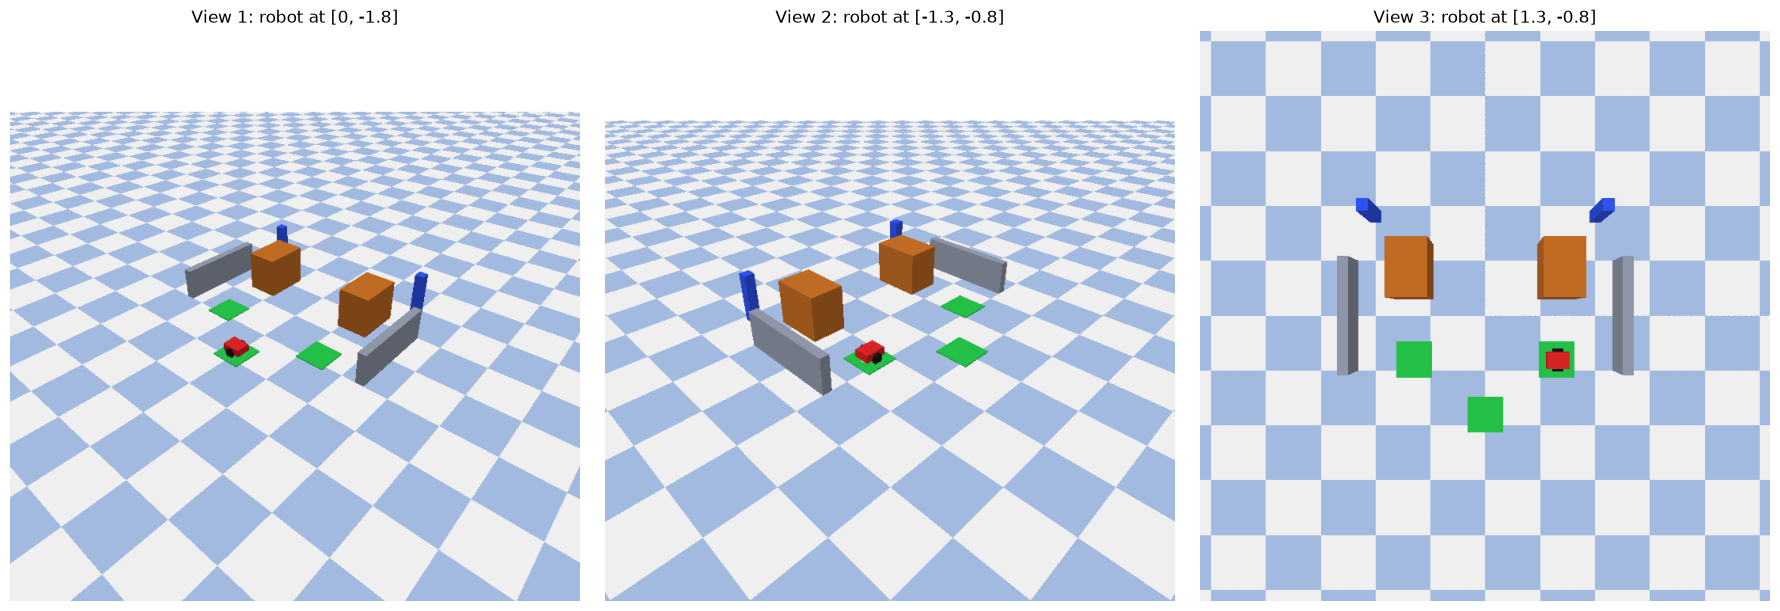

In [4]:
initial_positions = {b: p.getBasePositionAndOrientation(b)[0] for b in semantics}
views = [([6, -7, 6], [0, -1.8, 0.155]),
         ([-6, -6, 5], [-1.3, -0.8, 0.155]),
         ([0, 0, 9], [1.3, -0.8, 0.155])]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
projection = p.computeProjectionMatrixFOV(60, 1, 0.1, 30)
for i, (eye, robot_position) in enumerate(views):
    p.resetBasePositionAndOrientation(robot, robot_position, [0, 0, 0, 1])
    view = p.computeViewMatrix(eye, [0, 0, 0], [0, 1, 0] if i == 2 else [0, 0, 1])
    _, _, rgba, _, segmentation = p.getCameraImage(720, 720, view, projection,
        renderer=p.ER_TINY_RENDERER, flags=p.ER_SEGMENTATION_MASK_OBJECT_AND_LINKINDEX)
    rgba = np.asarray(rgba).reshape(720, 720, 4)
    plt.imsave(f"view_{i+1}.png", rgba)
    axes[i].imshow(rgba)
    axes[i].set_title(f"View {i+1}: robot at {robot_position[:2]}")
    axes[i].axis("off")
    # Segmentation encodes object ID in the lower 24 bits.
    mask = np.asarray(segmentation).reshape(720, 720)
    visible = set((mask[mask >= 0] & ((1 << 24) - 1)).tolist())
    assert set(semantics).issubset(visible), f"Objects missing in view {i+1}"
    assert robot in visible, f"Robot missing in view {i+1}"
    assert all(np.allclose(initial_positions[b], p.getBasePositionAndOrientation(b)[0]) for b in semantics)
    print(f"View {i+1} visibility/static-position checks passed; query:", nearest_object("target"))
plt.tight_layout()
plt.show()
assert len(models) >= 4 and len(semantics) >= 8
assert sum(p.getJointInfo(robot, j)[2] == p.JOINT_REVOLUTE for j in range(p.getNumJoints(robot))) == 2
print("Task 1 structural checks passed.")


## Reflection to complete after reviewing your run
- Explain why these roles and camera locations support warehouse inspection.
- Compare geometric nearest-target queries with camera-based target recognition. This notebook uses known simulator positions; it does not infer semantics from pixels.
- Record actual problems, changes and outcomes; do not invent failed attempts.
- Explain the limitation of repositioning the robot rather than driving it dynamically.
- Upload to Colab, run all cells, and confirm public viewer access before adding its link to the report.
